# Cardiovascular Disease Prediction: Data Analytics Life Cycle

This project identifies a cardiovascular disease outcome, audits and cleans the data, explores distributions and relationships, and builds two models from the core analytics families: **classification** for prediction and **clustering** for patient segmentation.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
DATA_PATH = "cardiovascular_disease_prediction.csv"
TARGET = "Cardiovascular_Disease"



In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target prevalence: {df[TARGET].mean():.2%}")

Dataset shape: 20,000 rows x 35 columns
Target prevalence: 30.60%


## 1. Business Understanding and Analytics Objective

The target variable is `Cardiovascular_Disease`, a binary indicator of whether a patient has cardiovascular disease. The predictive objective is to estimate disease status from demographic, clinical, lifestyle, and socioeconomic attributes. A secondary descriptive objective is to discover patient profiles using unsupervised clustering.

## 2. Data Understanding and Initial Audit

The audit checks structure, data types, missing values, duplicates, target balance, and numeric summary statistics before any transformation.

In [4]:
# display the data types of each column in the DataFrame
print("Column data types:")
display(df.dtypes.to_frame("dtype"))

Column data types:


,dtype
Patient_ID,int64
Age,int64
Gender,object
Height_cm,float64
Weight_kg,float64
BMI,float64
Blood_Pressure_Systolic,int64
Blood_Pressure_Diastolic,int64
Heart_Rate,int64
Cholesterol,int64


In [5]:
print(f"Duplicate rows: {df.duplicated().sum():,}")

Duplicate rows: 0


In [6]:
missing_summary = (
    df.isna().sum()
    .to_frame("missing_count")
    .assign(missing_percent=lambda table: 100 * table["missing_count"] / len(df))
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)

print("Missing-value summary:")
display(missing_summary)


Missing-value summary:


,missing_count,missing_percent
BMI,600,3.0
HDL,600,3.0
LDL,600,3.0
Triglycerides,600,3.0
Blood_Glucose,600,3.0
Physical_Activity,600,3.0
Sleep_Hours,600,3.0
Diet_Quality,600,3.0


In [7]:
print("Target balance:")
display(df[TARGET].value_counts(normalize=True).rename("proportion").to_frame())


Target balance:


,proportion
Cardiovascular_Disease,
0,0.694
1,0.306


In [8]:
display(df.describe(include="number").T.round(2))

,count,mean,std,min,25%,50%,75%,max
Patient_ID,20000.0,110000.50,5773.65,100001.00,105000.75,110000.50,115000.25,120000.0
Age,20000.0,52.53,19.06,20.00,36.00,52.00,69.00,85.0
Height_cm,20000.0,168.02,9.90,145.00,161.20,168.00,174.80,200.0
Weight_kg,20000.0,72.17,14.80,40.00,61.90,72.20,82.30,128.2
BMI,19400.0,25.83,6.15,10.20,21.50,25.50,29.80,56.5
Blood_Pressure_Systolic,20000.0,124.78,17.63,90.00,113.00,124.00,137.00,193.0
Blood_Pressure_Diastolic,20000.0,79.60,11.77,55.00,71.00,80.00,88.00,130.0
Heart_Rate,20000.0,74.49,9.98,45.00,68.00,75.00,81.00,112.0
Cholesterol,20000.0,204.89,39.53,120.00,177.00,204.00,232.00,350.0
HDL,19400.0,54.54,14.79,20.00,44.00,54.00,64.00,100.0


## 3. Data Cleaning and Preparation

Rows are deduplicated, the identifier is excluded from modeling, and missing values are imputed inside modeling pipelines to prevent information leakage. Numeric columns use the median; categorical columns use the most frequent category.

In [9]:
# Remove exact duplicates 
clean_df = df.drop_duplicates().copy()
clean_df = clean_df.drop(columns=["Patient_ID"])

X = clean_df.drop(columns=[TARGET])
y = clean_df[TARGET].astype(int)

In [10]:
# define modeling features

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)



In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Rows after deduplication: {len(clean_df):,}")
print(f"Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}")
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")

Rows after deduplication: 20,000
Numeric features: 17 | Categorical features: 16
Training rows: 16,000 | Test rows: 4,000


## 4. Exploratory Data Analysis and Visualization

The visual analysis focuses on the target balance, age distribution, clinical risk variables, and differences in selected numeric features between patients with and without cardiovascular disease.

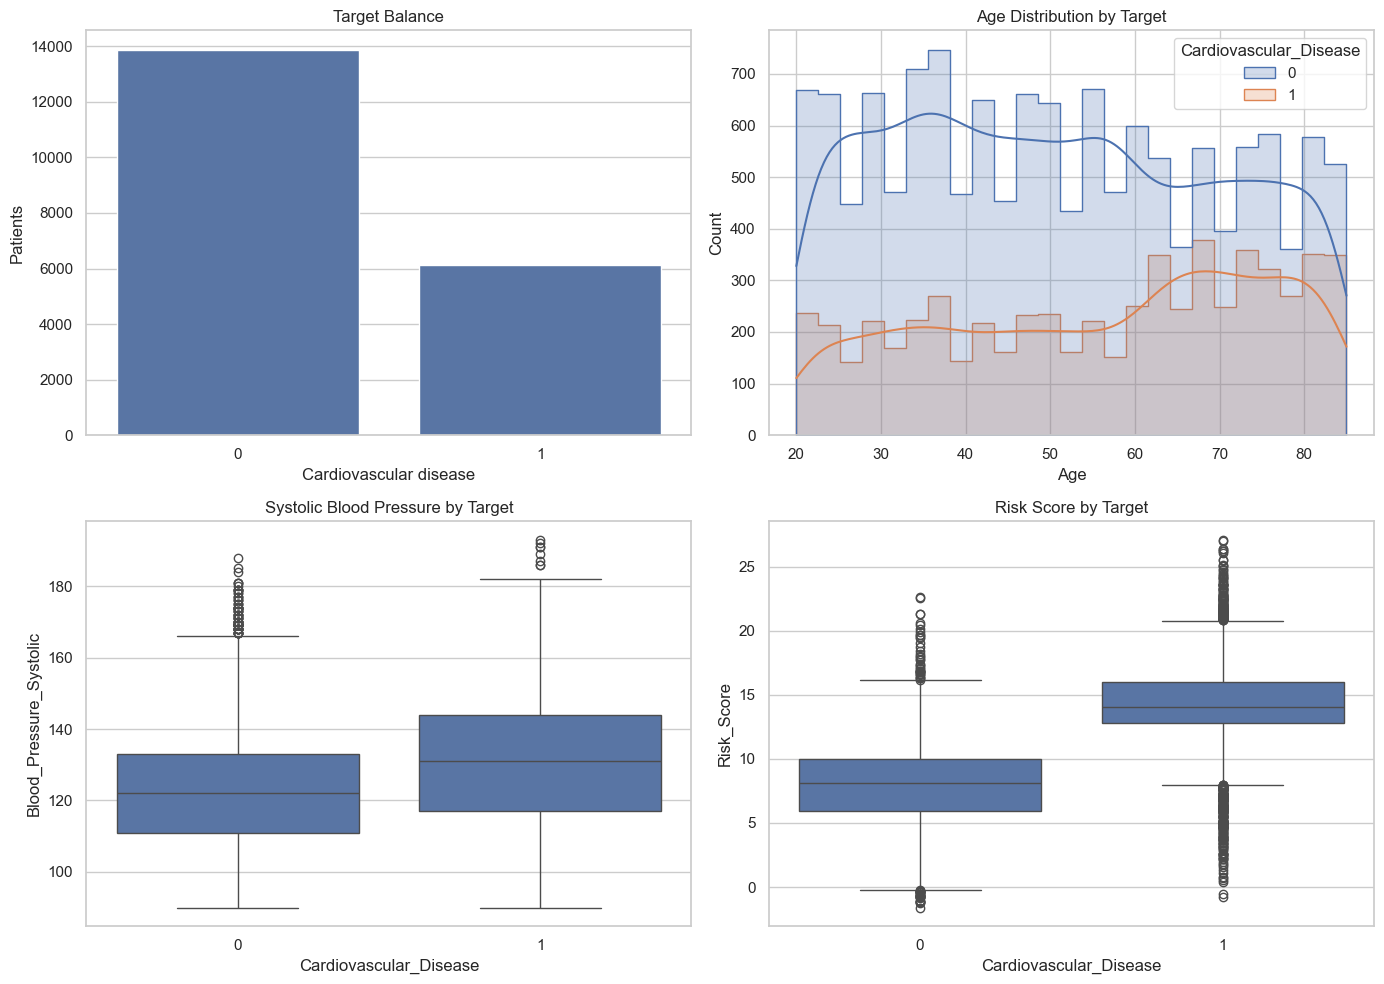

,Age,Blood_Pressure_Systolic,Cholesterol,Risk_Score
Cardiovascular_Disease,,,,
0,50.97,122.34,202.55,7.84
1,56.05,130.31,210.20,14.40


In [12]:
# Target balance and distributions of key clinical variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=clean_df, x=TARGET, ax=axes[0, 0])
axes[0, 0].set_title("Target Balance")
axes[0, 0].set_xlabel("Cardiovascular disease")
axes[0, 0].set_ylabel("Patients")

sns.histplot(data=clean_df, x="Age", hue=TARGET, bins=25, kde=True, element="step", ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution by Target")

sns.boxplot(data=clean_df, x=TARGET, y="Blood_Pressure_Systolic", ax=axes[1, 0])
axes[1, 0].set_title("Systolic Blood Pressure by Target")

sns.boxplot(data=clean_df, x=TARGET, y="Risk_Score", ax=axes[1, 1])
axes[1, 1].set_title("Risk Score by Target")

plt.tight_layout()
plt.show()

numeric_target_summary = (
    clean_df.groupby(TARGET)[["Age", "Blood_Pressure_Systolic", "Cholesterol", "Risk_Score"]]
    .mean()
    .round(2)
)
display(numeric_target_summary)

### EDA visualizations interpretations

- The **target-balance chart** shows that patients without cardiovascular disease are the larger group, while approximately 30.6% of patients have the disease. This means the target is somewhat imbalanced, so model performance should not be judged by accuracy alone.
- The **age distribution** compares the ages of patients with and without disease. The disease group is shifted toward older ages, suggesting that age may be useful for prediction, although the overlap shows that age alone cannot classify every patient.
- The **systolic blood-pressure boxplot** compares the median and spread of blood pressure across the two target groups. Patients with disease generally have higher blood pressure, but overlapping boxes and whiskers indicate that blood pressure is only one part of the risk pattern.
- The **risk-score boxplot** shows the clearest separation: patients with cardiovascular disease have higher typical risk scores. The remaining overlap means the score is informative but not perfect.

The table below the figure reports group means, which summarize these differences numerically. These are associations in this dataset, not evidence that any single variable causes cardiovascular disease.

In [13]:
# Compare selected categorical risk indicators with disease prevalence
categorical_checks = ["Hypertension", "Diabetes", "Smoking", "Family_History", "Chest_Pain"]
prevalence_by_category = {
    column: clean_df.groupby(column)[TARGET].mean().sort_values(ascending=False).round(3)
    for column in categorical_checks
}
for column, rates in prevalence_by_category.items():
    print(f"{column} - disease prevalence")
    display(rates.rename("prevalence").to_frame())

Hypertension - disease prevalence


,prevalence
Hypertension,
Yes,0.500
No,0.224


Diabetes - disease prevalence


,prevalence
Diabetes,
Yes,0.511
No,0.216


Smoking - disease prevalence


,prevalence
Smoking,
Yes,0.416
No,0.263


Family_History - disease prevalence


,prevalence
Family_History,
Yes,0.403
No,0.253


Chest_Pain - disease prevalence


,prevalence
Chest_Pain,
Yes,0.504
No,0.252


### Categorical prevalence results

Each table reports the proportion of patients with cardiovascular disease within a category. For example, comparing the `Yes` and `No` rows for hypertension shows whether disease prevalence differs between those groups. Higher prevalence in a category indicates an association with the target in this dataset, not a causal relationship.

The comparisons suggest higher disease prevalence among patients with hypertension, diabetes, smoking history, family history, or chest pain. These variables may help the classifier identify higher-risk patients, but the differences should be interpreted together with the other clinical and lifestyle features.

## 5. Predictive Model: Logistic Regression Classification

Logistic regression is a supervised classification model suitable for the binary target. The pipeline learns imputation, scaling, and one-hot encoding only from the training data, then evaluates generalization on the held-out test set.

In [14]:
# Train and evaluate the predictive classification model
classification_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
)
classification_model.fit(X_train, y_train)

y_pred = classification_model.predict(X_test)
y_probability = classification_model.predict_proba(X_test)[:, 1]

classification_metrics = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
    }
).round(3)
display(classification_metrics.to_frame("score"))
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

,score
Accuracy,0.954
Precision,0.951
Recall,0.895
ROC-AUC,0.951


              precision    recall  f1-score   support

  No disease       0.95      0.98      0.97      2776
     Disease       0.95      0.89      0.92      1224

    accuracy                           0.95      4000
   macro avg       0.95      0.94      0.94      4000
weighted avg       0.95      0.95      0.95      4000




### Classification model interpretation

The logistic regression classifier performs well on the held-out test set:

- **Accuracy = 0.954:** 95.4% of all test patients were classified correctly.
- **Precision = 0.951:** Of the patients predicted to have cardiovascular disease, 95.1% actually had the disease. A high precision means relatively few false alarms.
- **Recall = 0.895:** Of the patients who actually had cardiovascular disease, the model identified 89.5%. The remaining 10.5% were false negatives, so the model missed some disease cases.
- **ROC-AUC = 0.951:** The model separates positive and negative cases very well across different probability thresholds.

Overall, the classifier is strong for this dataset because accuracy, precision, recall, and ROC-AUC are all high. Recall is especially important in a health-related prediction task because missing a patient with the disease can be more serious than incorrectly flagging a healthy patient. If the priority were to reduce missed cases further, the classification threshold could be lowered, although this would normally reduce precision and create more false positives. 

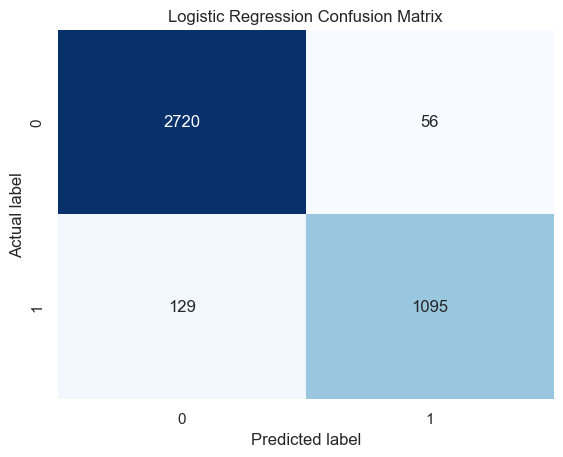

In [15]:
confusion = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

### Confusion Matrix Interpretation

The confusion matrix compares actual outcomes with the model's predictions:

- **True negatives:** patients without disease correctly identified as negative.
- **True positives:** patients with disease correctly identified as positive.
- **False positives:** patients without disease incorrectly flagged as positive. These are false alarms and affect precision.
- **False negatives:** patients with disease incorrectly predicted as negative. These missed cases affect recall.

The model's high precision means most positive predictions are correct, while its 89.5% recall means it identifies most, but not all, patients who actually have cardiovascular disease. In a screening context, reducing false negatives may be more important than minimizing false positives, so the prediction threshold could be adjusted based on the practical objective.

## 6. Descriptive Model: K-Means Clustering

K-means provides a second analytics model from the clustering family. It uses standardized numeric health and lifestyle measures, excluding the target, to group patients with similar profiles. The silhouette score helps compare candidate values of $k$.

In [16]:
cluster_features = [
    "Age",
    "BMI",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Heart_Rate",
    "Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Blood_Glucose",
    "Exercise_Days_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Risk_Score",
]
cluster_matrix = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
).fit_transform(clean_df[cluster_features])

In [17]:
# Determine the optimal number of clusters using silhouette scores and select the best k
candidate_k = range(2, 6)
silhouette_scores = {}
for k in candidate_k:
    candidate_model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    candidate_labels = candidate_model.fit_predict(cluster_matrix)
    silhouette_scores[k] = silhouette_score(cluster_matrix, candidate_labels)

silhouette_table = pd.Series(silhouette_scores, name="silhouette_score").round(3)
best_k = max(silhouette_scores, key=silhouette_scores.get)
cluster_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
clean_df["Cluster"] = cluster_model.fit_predict(cluster_matrix)

cluster_profile = (
    clean_df.groupby("Cluster")[cluster_features + [TARGET]]
    .mean(numeric_only=True)
    .round(2)
)
cluster_sizes = clean_df["Cluster"].value_counts().sort_index()
cluster_prevalence = clean_df.groupby("Cluster")[TARGET].mean().mul(100).round(1)

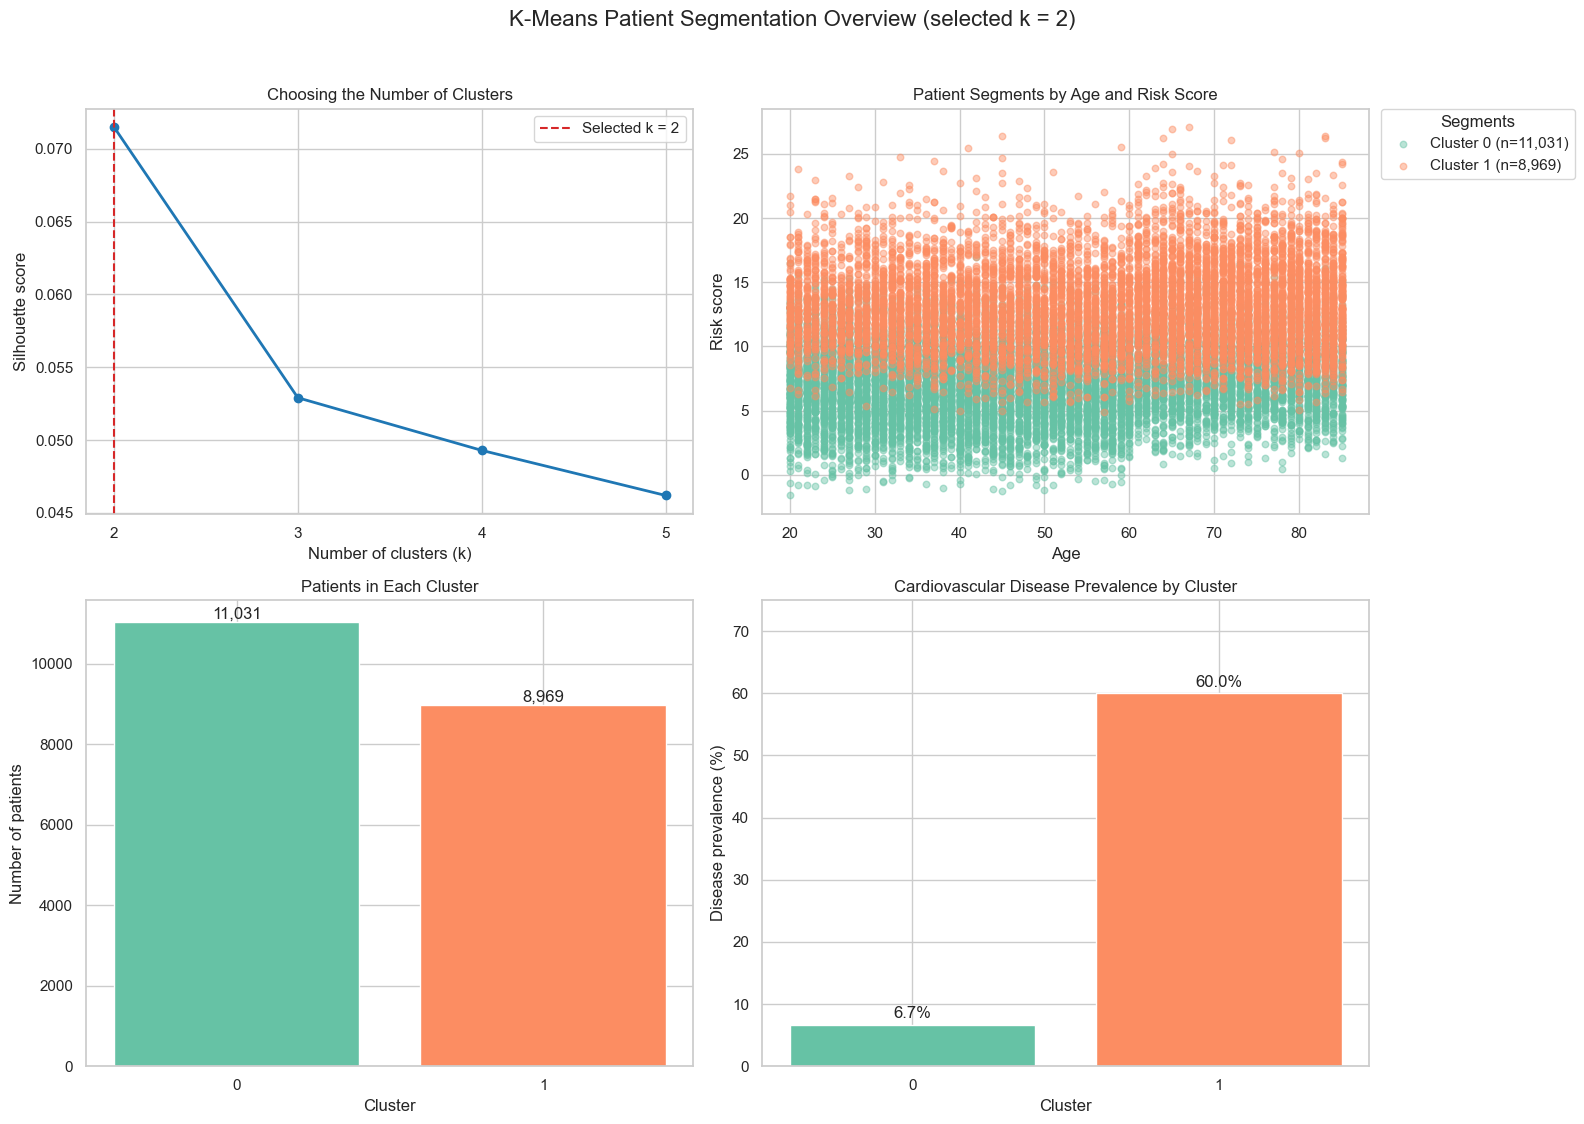

In [18]:
# Build a readable four-panel clustering diagnostic figure.
fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
    gridspec_kw={"height_ratios": [1, 1.15]},
)

axes[0, 0].plot(
    list(silhouette_scores),
    list(silhouette_scores.values()),
    marker="o",
    linewidth=2,
    color="#1f77b4",
)
axes[0, 0].axvline(best_k, linestyle="--", color="#d62728", label=f"Selected k = {best_k}")
axes[0, 0].set_title("Choosing the Number of Clusters")
axes[0, 0].set_xlabel("Number of clusters (k)")
axes[0, 0].set_ylabel("Silhouette score")
axes[0, 0].set_xticks(list(silhouette_scores))
axes[0, 0].legend(loc="best")

cluster_palette = sns.color_palette("Set2", n_colors=best_k)
for cluster_id in sorted(clean_df["Cluster"].unique()):
    cluster_rows = clean_df[clean_df["Cluster"] == cluster_id]
    axes[0, 1].scatter(
        cluster_rows["Age"],
        cluster_rows["Risk_Score"],
        s=22,
        alpha=0.45,
        color=cluster_palette[cluster_id],
        label=f"Cluster {cluster_id} (n={len(cluster_rows):,})",
    )
axes[0, 1].set_title("Patient Segments by Age and Risk Score")
axes[0, 1].set_xlabel("Age")
axes[0, 1].set_ylabel("Risk score")
axes[0, 1].legend(
    title="Segments",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
)

axes[1, 0].bar(
    cluster_sizes.index.astype(str),
    cluster_sizes.values,
    color=cluster_palette,
)
axes[1, 0].set_title("Patients in Each Cluster")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("Number of patients")
for index, value in enumerate(cluster_sizes.values):
    axes[1, 0].text(index, value + 100, f"{value:,}", ha="center")

axes[1, 1].bar(
    cluster_prevalence.index.astype(str),
    cluster_prevalence.values,
    color=cluster_palette,
)
axes[1, 1].set_title("Cardiovascular Disease Prevalence by Cluster")
axes[1, 1].set_xlabel("Cluster")
axes[1, 1].set_ylabel("Disease prevalence (%)")
axes[1, 1].set_ylim(0, max(cluster_prevalence.values) * 1.25)
for index, value in enumerate(cluster_prevalence.values):
    axes[1, 1].text(index, value + 1, f"{value:.1f}%", ha="center")

fig.suptitle(
    f"K-Means Patient Segmentation Overview (selected k = {best_k})",
    fontsize=16,
    y=1.02,
)
plt.tight_layout()
plt.show()



In [19]:
print(f"Selected k: {best_k}")
print("Silhouette scores:")
display(silhouette_table.to_frame())
print("Cluster profiles:")
display(cluster_profile)

Selected k: 2
Silhouette scores:


,silhouette_score
2,0.072
3,0.053
4,0.049
5,0.046


Cluster profiles:


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Risk_Score,Cardiovascular_Disease
Cluster,,,,,,,,,,,,,,,
0,48.82,24.75,118.97,79.06,74.55,199.24,56.63,114.69,151.35,95.14,3.77,63.53,7.07,7.19,0.07
1,57.09,27.18,131.93,80.25,74.42,211.84,51.97,125.89,149.51,118.36,3.19,55.06,6.93,13.11,0.60


### The clustering visuals

- The **silhouette-score panel** compares candidate values of $k$. A higher score means observations are more similar to their own cluster and more different from other clusters. The selected value is the highest tested score, but the low score of 0.072 means the separation is weak.
- The **scatter plot** places each patient by age and risk score. Color identifies the assigned cluster, and the legend is outside the plot so it does not hide observations. The two groups overlap because clustering used several standardized health and lifestyle variables, not just these two displayed dimensions.
- The **cluster-size panel** shows whether the groups are balanced. Very different sizes can indicate a small subgroup rather than two equally common patient profiles.
- The **prevalence panel** compares the percentage of cardiovascular disease cases in each cluster. This is a descriptive comparison, not proof that the cluster causes disease or should be used as a diagnosis.

In this dataset, the lower-risk cluster has lower average age, blood pressure, glucose, and risk score, while the higher-risk cluster has higher averages for these measures. Because the silhouette score is low, these differences should be treated as broad tendencies rather than sharply defined patient types.

### Data and modeling limitations

- The dataset has a 30.6% positive disease rate, so accuracy should be read alongside precision, recall, and ROC-AUC.
- Missing values are concentrated in eight columns at 3% each; imputation is performed within the pipeline rather than before the train/test split.
- The classification metrics are measured on one held-out split and should be confirmed with cross-validation and an external test set.
- our results should not be used for clinical decisions without external validation, calibration, fairness checks, and domain review.